In [48]:
import numpy as np
import pandas as pd
from src.utils.paths import EXTERNAL_DIR

In [49]:
path = EXTERNAL_DIR / "stations_coordinates.csv"
stations_coor_df = pd.read_csv(path)
stations_coor_df

,station_name,latitude,longitude
0,alipur,28.815339,77.153009
1,anand_vihar,28.647746,77.315450
2,ashok_vihar,28.696286,77.181552
3,bawana,28.776934,77.051134
4,chandni_chowk,28.659506,77.229525
5,dilshad_garden,28.683309,77.311648
6,dr_karni_singh_shooting_range,28.499934,77.267095
7,dtu,28.748759,77.117168
8,dwarka_sector_8,28.571401,77.069646
9,major_dhyan_chand_national_stadium,28.611214,77.237750


In [50]:
# Haversine Distance Function
def haversine(phi_1, lemda_1, phi_2, lemda_2):
    R = 6371.0  # Earth's radius in km (average)
    # equatorial radius-> 6,378 kilometers, polar radius-> 6,357 kilometers

    phi_1 = np.radians(phi_1)
    lemda_1 = np.radians(lemda_1)
    phi_2 = np.radians(phi_2)
    lemda_2 = np.radians(lemda_2)

    dis_lat = phi_1 - phi_2
    dis_lon = lemda_1 - lemda_2

    a = np.sin(dis_lat / 2) ** 2 + np.cos(phi_1) * np.cos(phi_2) * np.sin(dis_lon / 2) ** 2
    d = 2 * R * np.arcsin(np.sqrt(a))

    return d

# Euclidean distance function
def euclidean(phi_1, lemda_1, phi_2, lemda_2):
    dis_lat = phi_1 - phi_2
    dis_lon = lemda_1 - lemda_2
    dist = np.sqrt(dis_lat**2 + dis_lon**2)

    return dist

In [51]:
import os
from src.utils.paths import VISUALIZATION_DIR, EXTERNAL_DIR
import matplotlib.pyplot as plt
import seaborn as sns

def dist_plot(df, type):

    DISTANCE_MATRIX_DIR = VISUALIZATION_DIR / "distance_matrix"
    DISTANCE_MATRIX_DIR.mkdir(parents=True, exist_ok=True)

    df.to_csv(os.path.join(EXTERNAL_DIR, f"{type}_distance_matrix.csv"), columns=df.columns, index=True)

    plt.figure(figsize=(18,12))
    sns.heatmap(data=df, cmap='coolwarm', cbar_kws={'label': f'Distance in Kilometers (Km)'}, annot=True)
    plt.title(f"Heatmap of the {type} Distances between the AQI stations", fontsize=20, pad=4, fontweight='bold')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.ylabel("AQI station", fontsize=12, fontweight='bold')
    plt.xlabel("AQI station", fontsize=12, fontweight='bold')
    plt.tight_layout()

    plt.savefig(os.path.join(DISTANCE_MATRIX_DIR, f"{type}_distance_matrix.png"), dpi=300, bbox_inches='tight')
    plt.show()

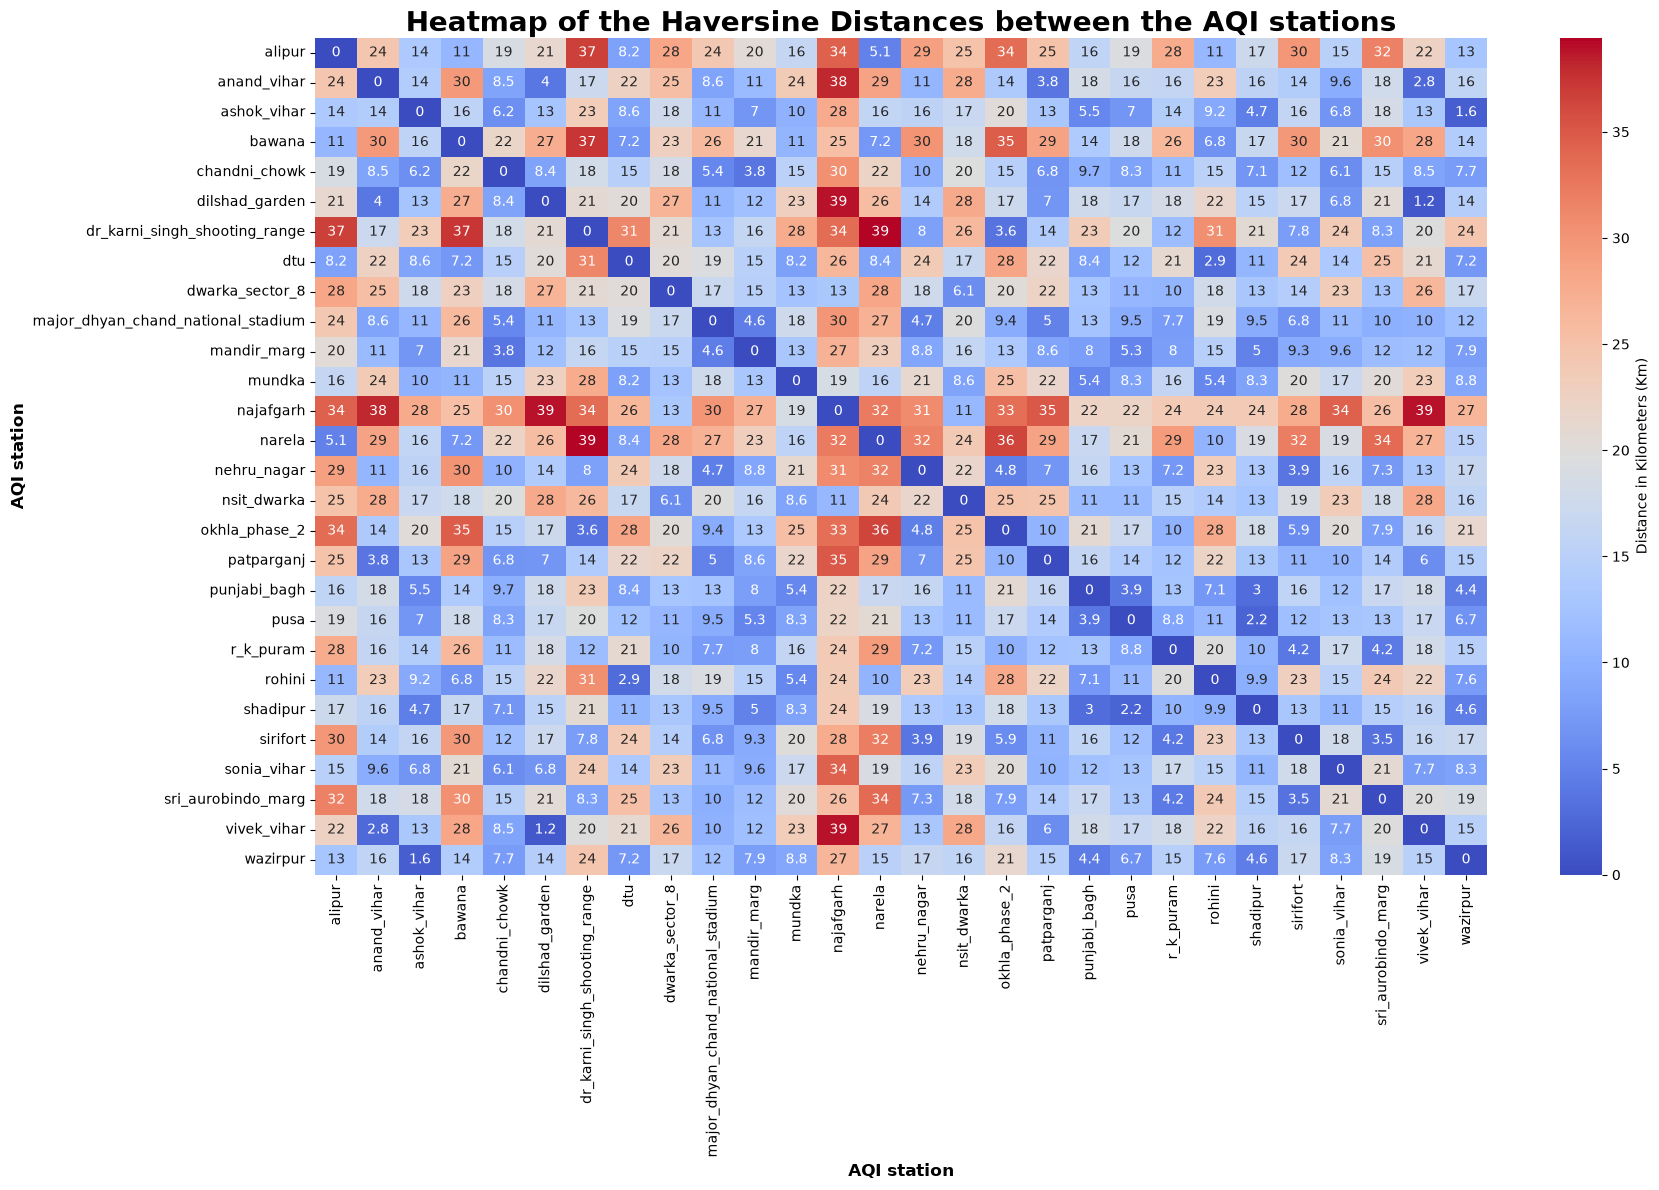

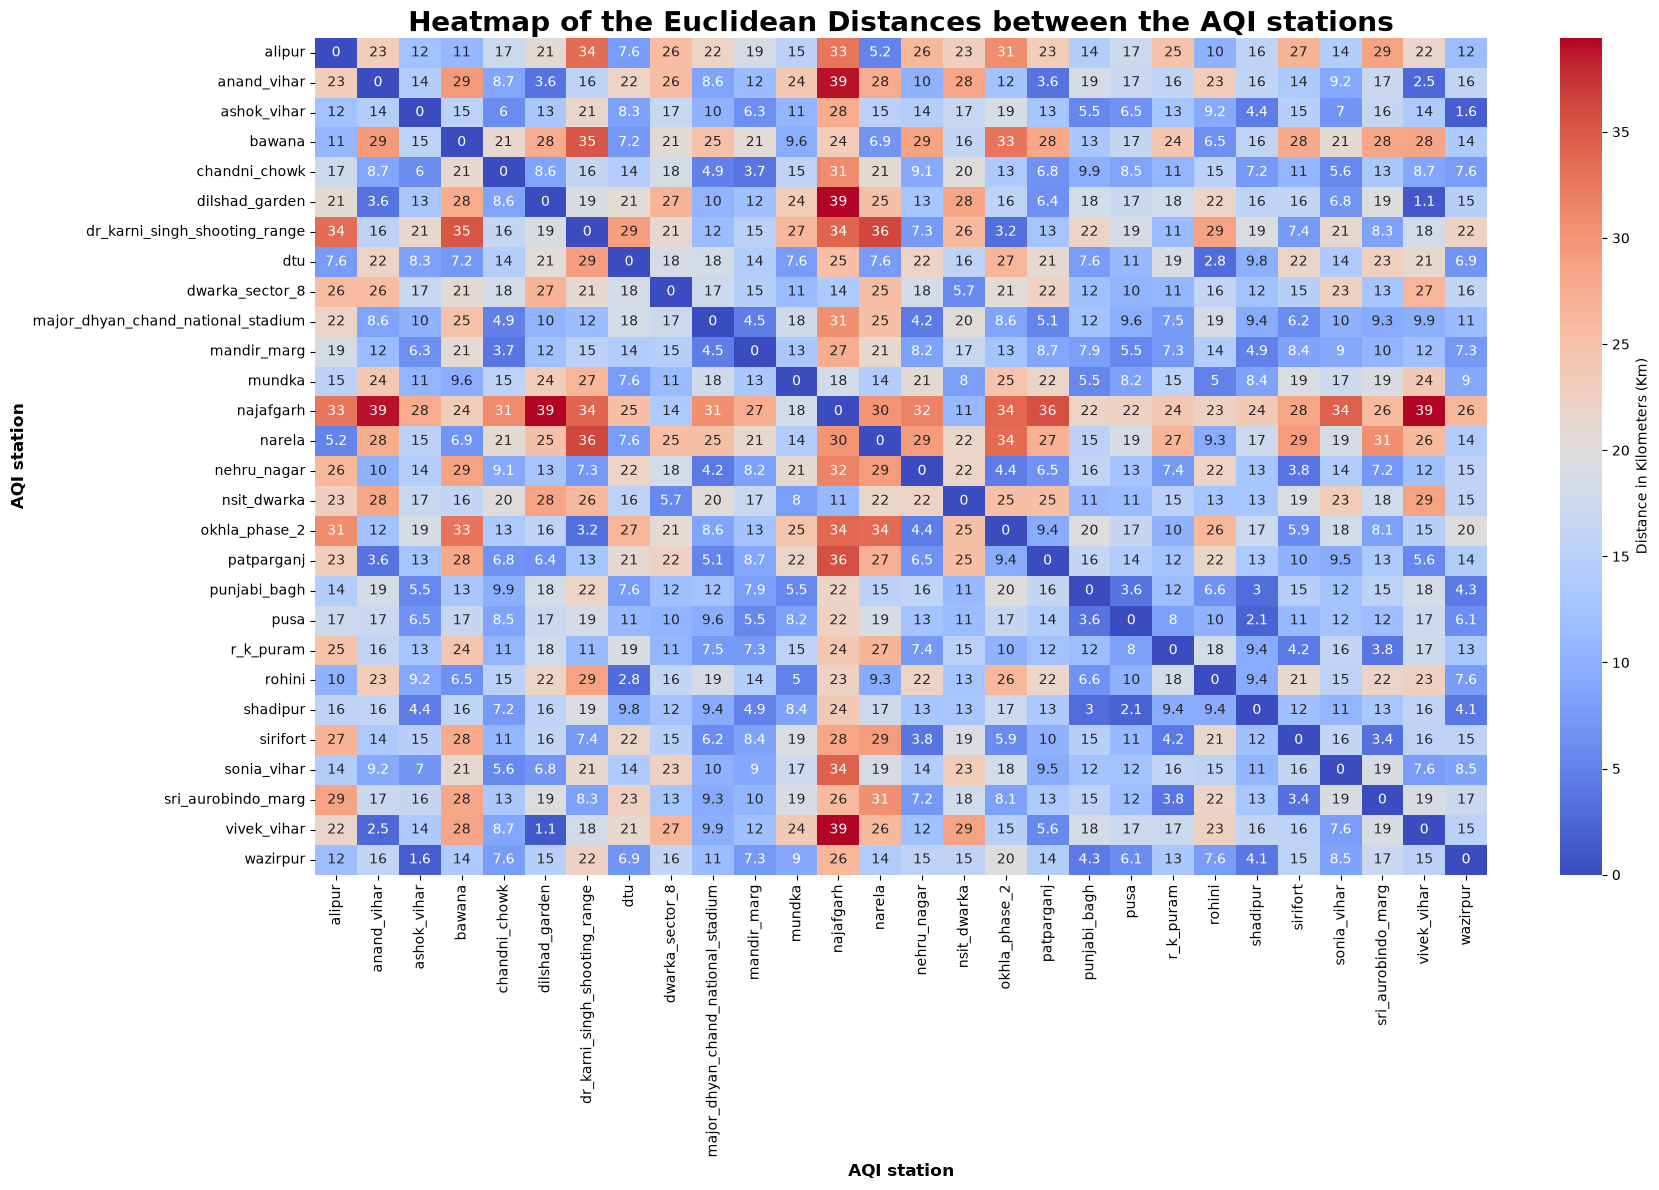

In [52]:
stations_coor_df = stations_coor_df.sort_values(by="station_name").reset_index(drop=True)

stations = stations_coor_df["station_name"].values
latitudes = stations_coor_df["latitude"].values
longitudes = stations_coor_df["longitude"].values

n = len(stations_coor_df)
haversine_distance_matrix = np.zeros((n, n))
euclidean_distance_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        haversine_distance_matrix[i, j] = haversine(
            latitudes[i], longitudes[i],
            latitudes[j], longitudes[j]
        )
        euclidean_distance_matrix[i, j] = euclidean(
            latitudes[i], longitudes[i],
            latitudes[j], longitudes[j]
        )*100

haversine_distance_df = pd.DataFrame(
    haversine_distance_matrix,
    index=stations,
    columns=stations
).round(2)
euclidean_distance_df = pd.DataFrame(
    euclidean_distance_matrix,
    index=stations,
    columns=stations
).round(2)

dist_plot(haversine_distance_df, "Haversine")
dist_plot(euclidean_distance_df, "Euclidean")



In [57]:
off_diag = haversine_distance_matrix[~np.eye(n, dtype=bool)]
thr = off_diag.mean() if n > 1 else 0.0
adj = (haversine_distance_matrix < thr).astype(np.float32)
np.fill_diagonal(adj, 1.0)